In [1]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import polars as pl

from src.data.diagnostics import check_overlap, compute_smd
from src.data.loader import ingest_hillstrom, load_config, stratified_split

cfg = load_config("config/hillstrom.yaml")
df = ingest_hillstrom(cfg)

/media/fahmi/data/ai/causal-uplift-policy/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Hillstrom dataset: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 443k/443k [00:01<00:00, 343kiB/s]


In [2]:
print(df.shape)
df.head()

(64000, 13)


recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend,treatment
i64,str,f64,i64,i64,str,i64,str,str,i64,i64,f64,i64
10,"""2) $100 - $200""",142.44,1,0,"""Surburban""",0,"""Phone""","""Womens E-Mail""",0,0,0.0,1
6,"""3) $200 - $350""",329.08,1,1,"""Rural""",1,"""Web""","""No E-Mail""",0,0,0.0,0
7,"""2) $100 - $200""",180.65,0,1,"""Surburban""",1,"""Web""","""Womens E-Mail""",0,0,0.0,1
9,"""5) $500 - $750""",675.83,1,0,"""Rural""",1,"""Web""","""Mens E-Mail""",0,0,0.0,1
2,"""1) $0 - $100""",45.34,1,0,"""Urban""",0,"""Web""","""Womens E-Mail""",0,0,0.0,1


In [3]:
df.group_by("segment").agg(
    pl.len().alias("n_users"),
    pl.col("visit").mean().alias("visit_rate"),
    pl.col("conversion").mean().alias("conversion_rate"),
    pl.col("spend").mean().alias("avg_spend")
)

segment,n_users,visit_rate,conversion_rate,avg_spend
str,u32,f64,f64,f64
"""Womens E-Mail""",21387,0.1514,0.008837,1.077202
"""No E-Mail""",21306,0.106167,0.005726,0.652789
"""Mens E-Mail""",21307,0.182757,0.012531,1.422617


,feature,mean_treated,mean_control,smd,abs_smd,is_balanced
0,history_segment_3) $200 - $350,0.194441,0.187749,0.017021,0.017021,True
1,history_segment_2) $100 - $200,0.218605,0.225377,-0.016297,0.016297,True
2,channel_Web,0.444002,0.436752,0.014604,0.014604,True
3,history,242.843737,239.350019,0.013671,0.013671,True
4,channel_Phone,0.436702,0.442306,-0.011291,0.011291,True
5,"history_segment_6) $750 - $1,000",0.029121,0.027380,0.010509,0.010509,True
6,"history_segment_7) $1,000 +",0.020963,0.019557,0.009975,0.009975,True
7,womens,0.547839,0.543926,0.007861,0.007861,True
8,history_segment_5) $500 - $750,0.076317,0.077916,-0.005995,0.005995,True
9,recency,5.749346,5.729641,0.005627,0.005627,True


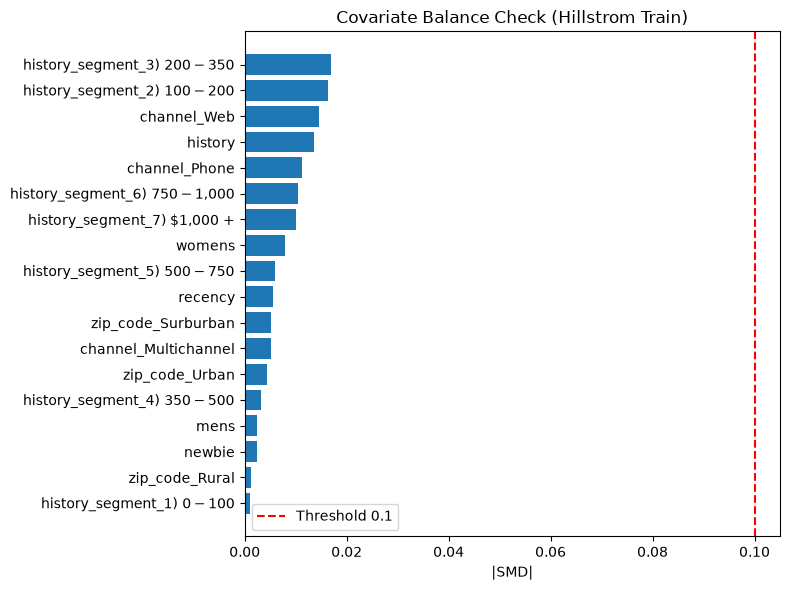

In [4]:
train_df, cal_df, test_df = stratified_split(
    df,
    stratify_cols=cfg["split"]["stratify_cols"],
    train_size=cfg["split"]["train_size"],
    cal_size=cfg["split"]["cal_size"],
    test_size=cfg["split"]["test_size"],
    seed=cfg["split"]["random_seed"]
)

smd_df = compute_smd(
    train_df,
    feature_cols=cfg["feature_cols"],
    treatment_col=cfg["treatment_col"],
    threshold=cfg["diagnostics"]["smd_threshold"]
)
display(smd_df)

fig, ax = plt.subplots(figsize=(8, 6))
plot_df = smd_df.sort_values("abs_smd", ascending=True)
ax.barh(plot_df["feature"], plot_df["abs_smd"])
ax.axvline(cfg["diagnostics"]["smd_threshold"], color="red", linestyle="--", label="Threshold 0.1")
ax.set_xlabel("|SMD|")
ax.set_title("Covariate Balance Check (Hillstrom Train)")
ax.legend()
plt.tight_layout()
plt.show()

Overlap Summary:  {'min': 0.6309887835226338, 'p05': 0.6528798873216918, 'median': 0.6665470230880969, 'p95': 0.6827702886537322, 'max': 0.7728742025589846, 'extreme_frac': 0.0}


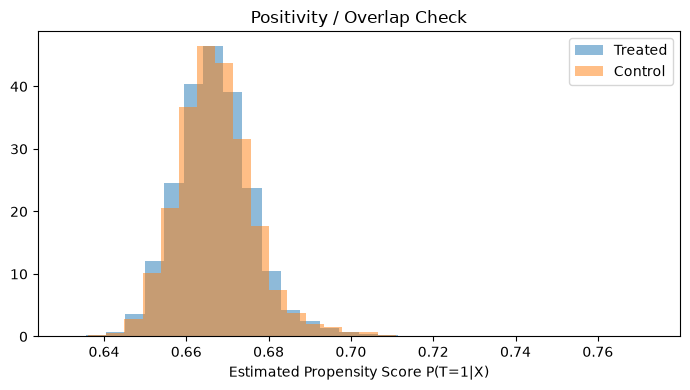

In [5]:
overlap_summary, propensity = check_overlap(
    train_df,
    feature_cols=cfg["feature_cols"],
    treatment_col=cfg["treatment_col"],
    clip_low=cfg["diagnostics"]["overlap_clip_low"],
    clip_high=cfg["diagnostics"]["overlap_clip_high"],
    n_splits=cfg["diagnostics"]["n_folds"],
    seed=cfg["split"]["random_seed"]
)
print("Overlap Summary: ", overlap_summary)

t_arr = train_df[cfg["treatment_col"]].to_numpy()
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(propensity[t_arr==1], bins=30, alpha=0.5, density=True, label="Treated")
ax.hist(propensity[t_arr==0], bins=30, alpha=0.5, density=True, label="Control")
ax.set_xlabel("Estimated Propensity Score P(T=1|X)")
ax.set_title("Positivity / Overlap Check")
ax.legend()
plt.tight_layout()
plt.show()